# Supervised Learning & Model Engineering - Group project
# STEP 7: Calibration diagnostics of the final model

**Dataset:** Adult / Census Income (OpenML, `name="adult"`, `version=2`)
**Group:** Clément, Eliott Monneraie, Lucas Stefani (lead for this step: Eliott, reviewed by all)
**Course reference:** Session 7 (reliability diagram, Brier score, ECE, Platt scaling, isotonic regression, "calibrate on unseen predictions", check segments, link between calibrated probabilities and the cost threshold)
**Code:** `src/calibration.py`. Settings: `config.yaml`, section `calibration`. Results: `reports/calibration/`. Tests: `tests/test_calibration.py`.

### How to read this notebook
Same labels as the previous steps: **What we see**, **What we decide**, **What could invalidate it**, **Note for STEP X**, **Limitation**.

### The question (requirement 9)
For the final model: plot a reliability curve, report the Brier score and the ECE, say whether the model is **over- or under-confident**, and whether we would **trust its probabilities as they are** for a business decision.

### The rule of this step
- **Diagnosis** of the final model: on its **test** probabilities, saved in STEP 6 (measure only).
- **Recalibration** (Platt, isotonic): learned and compared on the **development out-of-fold** predictions of STEP 5, with the same 5 folds. Session 7: *"never learn the calibration map from the same fitted predictions used to train the base model"*, and the test set *"remains untouched for final evaluation"*.
- No model is refitted: the step reads the probabilities saved in STEPS 5 and 6.

In [1]:
# ===================== Setup =====================
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.data import load_config
from src.calibration import run_calibration, save_results, reliability_table, expected_calibration_error

warnings.filterwarnings("ignore")
cfg = load_config()
FIG_DIR = cfg["paths"]["figures_dir"]
COLORS = {"raw": "#fc8d62", "platt": "#8da0cb", "isotonic": "#66c2a5", "dev": "#999999"}
sns.set_theme(style="whitegrid")

def savefig(name: str) -> None:
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")

r = run_calibration(cfg)          # reads saved probabilities only: no model is refitted
save_results(cfg, r)
y_test, p_test = r["y_test"], r["p_test_by"]["raw"]
print(f"Final model: {r['model']} | test: {len(y_test):,} people | development (out-of-fold): {len(r['y_dev']):,} people")

Final model: lightgbm | test: 9,758 people | development (out-of-fold): 39,032 people


---
# Part A - Why calibration matters for the bank

Our ranking is already measured (PR-AUC 0.763). Calibration asks another question (Session 7): **when the model says 30%, are about 30% of these people really >50K?**

It matters here for two reasons:
1. **The decision uses the size of the probability.** We call when P(>50K) >= 0.15. If the model's "15%" really meant 5% or 30%, the threshold would not mean what the business cost assumes.
2. **Advisors read the number.** A prospect shown at 80% should be a much safer call than one at 20%. If 80% really meant 60%, the bank would plan its time on false numbers.

---
# Part B - Reliability diagram

,bin,n,mean_predicted,observed,gap
0,0.0-0.1,4979,0.026,0.024,-0.002
1,0.1-0.2,987,0.147,0.163,+0.016
2,0.2-0.3,626,0.248,0.267,+0.018
3,0.3-0.4,608,0.349,0.350,+0.001
4,0.4-0.5,507,0.451,0.394,-0.056
5,0.5-0.6,443,0.550,0.512,-0.037
6,0.6-0.7,469,0.648,0.633,-0.015
7,0.7-0.8,508,0.751,0.728,-0.023
8,0.8-0.9,394,0.846,0.896,+0.050
9,0.9-1.0,237,0.932,0.958,+0.026


Figure saved: reports/figures/22_reliability_diagram_final_model.png


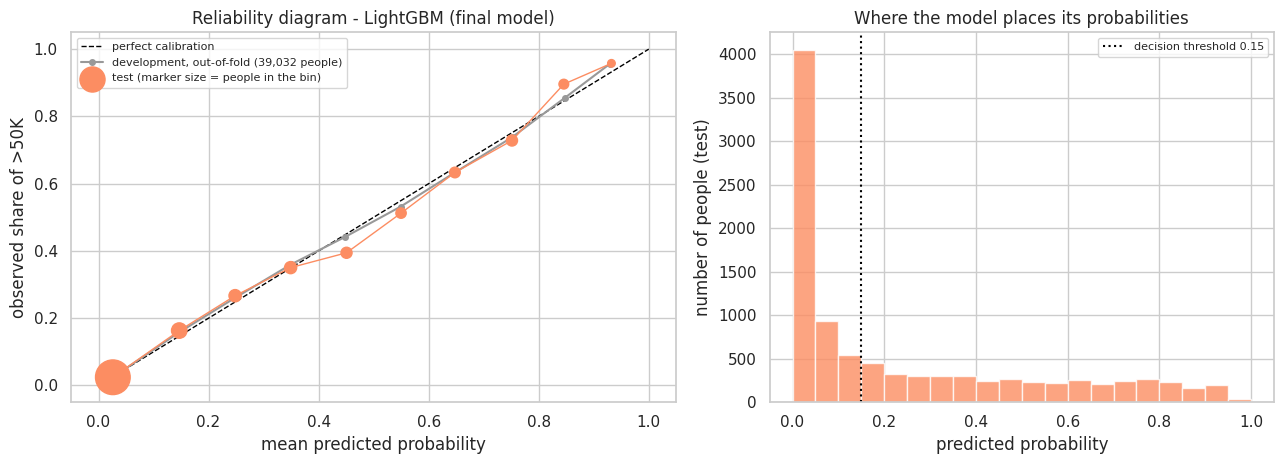

In [2]:
# ===================== B. Reliability diagram of the final model (test set) =====================
t_test, t_dev = r["test_reliability"], r["dev_reliability"]
display(t_test.style.format({"mean_predicted": "{:.3f}", "observed": "{:.3f}", "gap": "{:+.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ax.plot([0, 1], [0, 1], "--", color="black", lw=1, label="perfect calibration")
ax.plot(t_dev["mean_predicted"], t_dev["observed"], "o-", color=COLORS["dev"], ms=4,
        label="development, out-of-fold (39,032 people)")
ax.scatter(t_test["mean_predicted"], t_test["observed"], s=t_test["n"] / 8, color=COLORS["raw"], zorder=3,
           label="test (marker size = people in the bin)")
ax.plot(t_test["mean_predicted"], t_test["observed"], color=COLORS["raw"], lw=1)
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed share of >50K")
ax.set_title("Reliability diagram - LightGBM (final model)"); ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ax.hist(p_test, bins=20, range=(0, 1), color=COLORS["raw"], alpha=0.8)
ax.axvline(0.15, color="black", ls=":", label="decision threshold 0.15")
ax.set_xlabel("predicted probability"); ax.set_ylabel("number of people (test)")
ax.set_title("Where the model places its probabilities"); ax.legend(fontsize=8)
savefig("22_reliability_diagram_final_model")
plt.show()

**What we see.**
- On the **development set** (grey line, 39,032 people, out-of-fold), the curve is almost on the diagonal: every bin is within 3 points of perfect.
- On the **test set** (orange), most bins are also close (within 2 points), with three visible gaps:
  - 0.4-0.5: predicted 45%, observed 39% (507 people): the model says a bit more than reality;
  - 0.5-0.6: 55% vs 51% (443 people), same direction;
  - 0.8-0.9: predicted 85%, observed 90% (394 people): the model says a bit less than reality.
- These gaps **do not appear on the development set**, which has 4 times more people per bin, and they go in **opposite directions**. So they do not show a systematic over- or under-confidence; they are more likely variation of this test sample (about 400-500 people per bin) than a property of the model. Session 7: always look at the counts before trusting a point. We still stay cautious: in the middle range, a probability can be off by about 5 points.
- The histogram: half of the people get less than 10% (clear "no"), and the rest is spread over the whole range. The threshold 0.15 sits just after the large mass of low probabilities.

**What we decide.** No systematic over- or under-confidence: the curve does not lie consistently below the diagonal (over-confident) or above it (under-confident). The model is **well calibrated overall**, with small local deviations on the test set.

---
# Part C - Brier score and ECE

In [3]:
# ===================== C. Brier score and ECE =====================
raw = r["test_table"].set_index("method").loc["raw"]
prev = raw["observed_rate"]
dev_ece = expected_calibration_error(r["y_dev"], r["p_dev"], r["n_bins"])
print(f"Brier score (test)                         : {raw['brier']:.4f}")
print(f"  reference: same probability for everyone : {prev * (1 - prev):.4f}  (= prevalence x (1 - prevalence))")
print(f"ECE, 10 bins (test)                        : {raw['ece']:.4f}   (development, out-of-fold: {dev_ece:.4f})")
print(f"Mean predicted probability (test)          : {raw['mean_predicted']:.3f}  vs observed share {prev:.3f}")

Brier score (test)                         : 0.1022
  reference: same probability for everyone : 0.1821  (= prevalence x (1 - prevalence))
ECE, 10 bins (test)                        : 0.0130   (development, out-of-fold: 0.0070)
Mean predicted probability (test)          : 0.241  vs observed share 0.239


**What we see.**
- **Brier score 0.102**, against 0.182 for a model giving everyone the same 23.9% (the "constant base-rate predictor" of Session 7). Lower is better: our probabilities are much more informative than the average.
- **ECE 0.013** on test (0.007 on the development set): on average, the predicted probability is about 1 point away from the observed share.
- On average the model predicts 24.1% of >50K for 23.9% observed: no global bias.

**What we decide.** These values confirm the diagram. The Brier score mixes calibration and ranking (Session 7), the ECE measures calibration only: both are low.

---
# Part D - Should we recalibrate? (decided on the development set)

Session 7 offers two corrections, both learned on predictions the model did not train on:
- **Platt scaling**: p_cal = sigmoid(A s + B), with s = log(p / (1 - p)) the model's score. Two parameters. **A = 1 and B = 0 means "nothing to correct"**; A < 1 means the model was too extreme (over-confident), A > 1 not extreme enough.
- **Isotonic regression**: a step function that only goes up. More flexible, needs more data, risk of fitting noise.

We use the same 5 folds as before: for each fold, the map is learned on the out-of-fold predictions of the 4 other folds and measured on this fold. **Rule:** a calibrator is kept only if it lowers the Brier score on at least 4 of the 5 folds (same "regular gain" logic as STEPS 4 and 5).

In [4]:
# ===================== D. Should we recalibrate? Decided on the development set =====================
cv = r["cv_table"]
summary = cv.groupby("method")[["brier", "ece", "pr_auc"]].agg(["mean", "std"])
display(summary.style.format("{:.4f}"))
wide = cv.pivot(index="fold", columns="method", values="brier")
for m in ("platt", "isotonic"):
    print(f"{m:9s}: lower Brier than raw on {int((wide[m] < wide['raw']).sum())}/5 folds")
print("\nPlatt parameters learned on 4 folds (A, B):", [(round(a, 3), round(b, 3)) for a, b in r["platt_ab_per_fold"]])
print(f"Decision rule: keep a calibrator only if it lowers the Brier score on >= {cfg['calibration']['min_folds_better']}/5 folds")
print(f"-> chosen on the development set: {r['chosen'].upper()}")

platt    : lower Brier than raw on 1/5 folds
isotonic : lower Brier than raw on 1/5 folds

Platt parameters learned on 4 folds (A, B): [(1.023, 0.006), (1.021, 0.012), (1.013, 0.019), (1.015, 0.011), (1.005, 0.006)]
Decision rule: keep a calibrator only if it lowers the Brier score on >= 4/5 folds
-> chosen on the development set: RAW


**What we see.**
- **Platt learns A between 1.005 and 1.023 and B between 0.006 and 0.019**: almost exactly "no correction". The model is already calibrated, Platt has nothing to fix.
- Platt: same Brier as raw (0.1035) and lower on only 1 fold out of 5. Isotonic: slightly worse Brier (0.1037), lower on only 1 fold, and **PR-AUC drops** from 0.752 to 0.743, because the step function gives the same probability to many people, so the ranking loses detail.

**What we decide.** We **keep the raw probabilities of LightGBM** (decision 46). No calibrator brings a regular gain, and isotonic damages the ranking.

**Why LightGBM is already calibrated.** It is trained by minimising the log-loss, without class weights or SMOTE (decisions 29 and 36). The log-loss rewards honest probabilities. STEP 4 kept "threshold only" precisely to keep the probabilities intact: this result confirms that choice. (Session 7's notebook uses a Random Forest with `class_weight="balanced"`, a typical case of distorted probabilities.)

---
# Part E - Before / after on the test set (for information)
The maps are learned on all development out-of-fold predictions and applied to the test probabilities. This is a **measure**, not a choice: the choice was made in Part D.

,brier,ece,pr_auc,roc_auc,mean_predicted
method,,,,,
raw,0.1022,0.0130,0.7626,0.9071,0.2412
platt,0.1023,0.0132,0.7626,0.9071,0.2415
isotonic,0.1022,0.0077,0.7539,0.9068,0.2413


Figure saved: reports/figures/23_recalibration_test.png


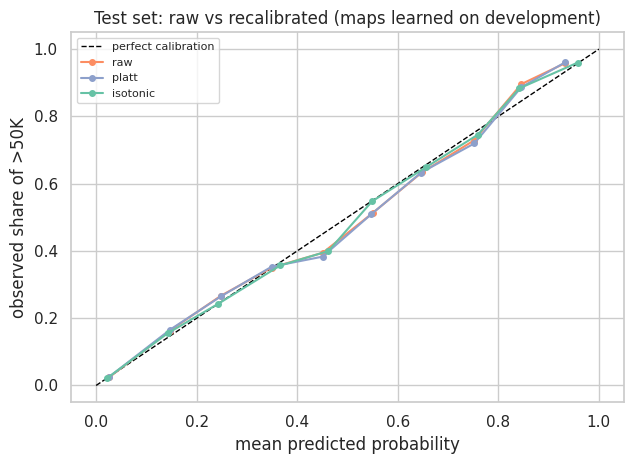

In [5]:
# ===================== E. Before / after on the test set (measured, not used to choose) =====================
display(r["test_table"].set_index("method")[["brier", "ece", "pr_auc", "roc_auc", "mean_predicted"]]
        .style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.plot([0, 1], [0, 1], "--", color="black", lw=1, label="perfect calibration")
for m in ("raw", "platt", "isotonic"):
    t = reliability_table(y_test, r["p_test_by"][m], r["n_bins"])
    ax.plot(t["mean_predicted"], t["observed"], "o-", color=COLORS[m], ms=4, label=m)
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed share of >50K")
ax.set_title("Test set: raw vs recalibrated (maps learned on development)"); ax.legend(fontsize=8)
savefig("23_recalibration_test")
plt.show()

**What we see.**
- Platt: Brier and ECE unchanged (0.102, 0.013). The three curves almost overlap.
- Isotonic: same Brier, lower ECE on this test sample (0.008), but lower PR-AUC (0.754 instead of 0.763).

**What we decide.** The test confirms that recalibration buys nothing that matters. Isotonic's lower ECE on test is not a reason to switch: it was not better on the development set (Part D), and choosing it now would mean choosing on the test set. It also costs ranking quality.

---
# Part F - Link with the business threshold (Session 7)

With calibrated probabilities, the threshold can be **computed directly from the costs** (Session 7, "simplified Bayes decision rule"):
- calling a person with probability p costs, on average, 1 x (1 - p) (a useless call if they are <=50K);
- not calling costs, on average, 5 x p (a missed wealthy prospect);
- calling is worth it when 1 x (1 - p) <= 5 x p, i.e. when **p >= 1/6 = 0.167**.

STEP 4 found the threshold by trying every value on the out-of-fold predictions: **0.15**, inside a flat zone of 0.13-0.20 where the cost hardly changes.

**What we see.** The theoretical threshold (0.167) and the one found on the data (0.15) agree. This is another sign that the probabilities can be read at face value: "15%" really means about 15%.

**What we decide.** We keep 0.15 (decision 40, chosen on the data). The agreement with 1/6 is a cross-check we can show to the business: the threshold is not an arbitrary number, it follows from "a missed wealthy prospect costs 5 calls".

---
# Part G - Calibration by sex (Session 7: check segments)

In [6]:
# ===================== G. Calibration by sex (Session 7: check segments) =====================
display(r["segments"].set_index("sex")[["n", "mean_predicted", "observed_rate", "brier", "ece"]]
        .style.format({"mean_predicted": "{:.3f}", "observed_rate": "{:.3f}", "brier": "{:.4f}", "ece": "{:.4f}"}))

,n,mean_predicted,observed_rate,brier,ece
sex,,,,,
Male,6432,0.310,0.304,0.1249,0.0222
Female,3326,0.108,0.115,0.0583,0.0136


**What we see.**
- Men (6,432): mean predicted 31.0%, observed 30.4%: **slightly over-estimated** (+0.7 point).
- Women (3,326): mean predicted 10.8%, observed 11.5%: **slightly under-estimated** (-0.7 point).
- ECE: 0.022 for men, 0.014 for women. Both small, but the overall calibration hides two small opposite errors.

**What we decide.** Not a reason to recalibrate by group (the gaps are small, and the model does not use `sex`). But the direction matters for STEP 9: if women's probabilities are slightly too low, fewer women may cross the 0.15 threshold than their real rate would justify.

**Note for STEP 9.** Check the recall by sex (share of wealthy women found vs wealthy men found) at the threshold 0.15. "Calibration within groups" is one of the fairness views to discuss.

---
# Part H - Answer to requirement 9

**Over- or under-confident?** Neither in a systematic way. The reliability curve follows the diagonal on the development set (39,032 people) and stays close on the test set (ECE 0.013, Brier 0.102 vs 0.182 for a constant model). Platt scaling finds A = 1.02, B = 0.01, i.e. almost no correction. The local gaps on the test set (over-estimated around 45-55%, under-estimated around 85%) are not present on the development set (4 times more people per bin) and go in opposite directions: not a systematic pattern.

**Would we trust the probabilities as they are?** **Yes, for the decision we make**: "call when P >= 0.15". The threshold derived from the costs on calibrated probabilities (1/6) matches the one found on the data (0.15). For uses that read the exact value (for example "this prospect has 47%"), we would communicate ranges rather than exact percentages, given the +/- 5 points seen in some test bins.

**What could invalidate it** (Session 7, "calibration is not permanent"): the data are from the 1994 census. On today's prospects the share of >50K and the profiles would differ, so calibration should be re-checked on recent data before any real use.

---
# Part I - Decisions log for STEP 7 (copied into DECISIONS.md)

| # | Decision | Where |
|---|---|---|
| 45 | Diagnosis of the final model on its test probabilities (STEP 6): reliability diagram (10 equal-width bins, with counts and histogram), Brier score, ECE | `src/calibration.py`, notebook 07 B-C |
| 46 | No recalibration: Platt and isotonic, learned on development out-of-fold predictions and compared with the same 5 folds, lower the Brier score on only 1/5 folds; Platt A = 1.02, B = 0.01 (nothing to correct); isotonic lowers PR-AUC (0.752 -> 0.743) | `choose_method`, notebook 07 D |
| 47 | Result: Brier 0.102 (constant model 0.182), ECE 0.013 on test (0.007 on development); no systematic over- or under-confidence; probabilities trusted for the 0.15 decision | notebook 07 H |
| 48 | Cross-check: cost-based threshold on calibrated probabilities = 1/(1+5) = 0.167, consistent with 0.15 found on the data (flat zone 0.13-0.20) | `bayes_threshold`, notebook 07 F |
| 49 | Calibration by sex: men slightly over-estimated (31.0% vs 30.4%), women slightly under-estimated (10.8% vs 11.5%); input for STEP 9 | notebook 07 G |